# Polyp Segmentation: CNN 3종 vs Transformer 3종

**목적**: Kaggle 용종 분할 데이터에서 6개 모델의 성능과 실패 양상을 동일 조건에서 비교한다. 단순 순위뿐 아니라 작은 용종, 경계, 과분할/미분할, 계산 비용을 해석한다.

- CNN: U-Net, PraNet, HarDNet-MSEG
- Transformer: DINOv2, SegFormer, Polyp-PVT
- 커널: **Python (scrna)** / 학습 장치: **물리 GPU 1만 사용**
- 결정된 실행 범위: 실제 학습 + 분석 + 모델별 CSV 6개 생성. **Kaggle 업로드는 하지 않는다.**
- 대회 API 확인: 평가 지표 Dice, 마감 2026-04-29 06:00 KST. 마감 후 연구용 비교이다.

[대회](https://www.kaggle.com/competitions/polyp-segmentation) | [실행 코드](./polyp_benchmark.py) | [의존성](./requirements-polyp.txt)

> 아직 6개 학습이 끝나지 않았다면 우승 모델이나 최종 수치를 주장하지 않는다. 모든 결과는 실제 체크포인트에서 계산한다.

## 1. 사전에 고정한 실험 프로토콜

| 항목 | 조건 |
|---|---|
| 분할 | 정렬된 800장에 NumPy default_rng(seed=42) 순열, train 640 / validation 160 |
| 공통 입력 | RGB 448×448, ImageNet mean/std; 마스크는 nearest resize 후 >127 |
| 증강 | train에서만 90도 회전, 수평·수직 반전, 밝기·대비 0.85–1.15 |
| 학습 | AdamW, lr=1e-4, weight decay=1e-4, cosine scheduler |
| 배치 | micro batch 4, accumulation 2: effective batch 8 |
| 예산 | 최대 50 epoch, patience 10, min_delta=1e-4 |
| 손실 | BCE + soft Dice; 여러 출력은 손실을 평균해 deep supervision |
| 모델 선택 | threshold=0.5, 원본 해상도 validation mean Dice 최고 epoch |
| 평가 | mean Dice/IoU/precision/recall, global Dice, boundary F1 |
| 테스트 | validation과 동일한 원본 해상도 복원·0.5 threshold, TTA/후처리/앙상블 없음 |
| 저장 | epoch별 이력, best/last checkpoint, 원본 크기 검증 마스크, 200행 CSV |

각 모델에 같은 분할·학습 조건·예산을 적용하되, 이는 각 논문의 학습법을 완전히 재현하는 실험은 아니다. 모델별로 원래의 다중 출력 구조는 유지한다. early stopping을 사용하므로 실제 학습 epoch 수는 다를 수 있다.

### 수치 안정성 사전 점검

실제 GPU 1에서 448×448, batch 4로 여섯 모델의 forward·backward·optimizer step을 확인했다. Polyp-PVT는 FP16 loss scaling에서 gradient overflow가 관측되어, 특정 모델만 예외 처리하지 않고 **모든 모델에 BF16 autocast를 공통 적용**한다. RTX A5000의 BF16 지원 여부를 실행 시 확인하며, BF16에서는 GradScaler를 비활성화한다. 손실 계산과 probability/metric 계산은 float32로 수행한다. NaN/Inf 손실·gradient는 오류로 중단하고 기록한다.

### 모델을 정확히 구분하기

| 모델 | 이 실험에서 사용하는 구성 | 초기화 |
|---|---|---|
| U-Net | 5단계 U자형 encoder/decoder, base channel 32, BatchNorm, padded conv | 무작위; 원 논문의 64채널/valid-conv 버전과 다름 |
| PraNet | 공식 Res2Net-50 encoder + reverse-attention decoder | ImageNet encoder만 |
| HarDNet-MSEG | 공식 HarDNet-68 + MSEG decoder | ImageNet encoder만 |
| DINOv2 | ViT-S/14, 3·6·9·12번째 block feature + 학습 가능한 다층 분할 decoder | 일반 DINOv2 사전학습 encoder만 |
| SegFormer | MiT-B2 + 공식 SegFormer decode head | ImageNet MiT encoder만; ADE20K segmentation 가중치 아님 |
| Polyp-PVT | 공식 PVTv2-B2 + CFM/CIM/SAM | ImageNet encoder만 |

DINOv2는 분할 모델명이 아니라 표현학습 encoder이므로 **DINOv2 + decoder** 결과로 해석해야 한다. Transformer 3종 역시 모두 동일한 순수 ViT 구조는 아니다. 모든 encoder를 fine-tuning한다.

**누수 방지**: Kvasir/용종 segmentation으로 사전학습된 전체 모델은 사용하지 않는다. Kaggle Test 또는 sample_submission의 target은 학습·평가 정답으로 사용하지 않는다. 일반 사전학습 corpus에 이 이미지들이 있었는지까지 완전히 배제할 수는 없다.

**라이선스**: [PraNet](https://github.com/DengPingFan/PraNet), [Polyp-PVT](https://github.com/DengPingFan/Polyp-PVT)는 연구·교육용 사용 제한이 있다. [HarDNet-MSEG](https://github.com/james128333/HarDNet-MSEG)는 Apache-2.0이다. 이 노트북은 로컬 연구용이며 CSV 생성이 Kaggle 제출 자격을 보증하지 않는다. 특히 Kaggle의 OSI 라이선스 조건과 상충할 수 있으므로 제출/공유/상업 이용 전 별도 확인이 필요하다. 원본 코드·README·라이선스를 보존하고, import와 하드코딩된 가중치 로딩만 수정한다. 소스 commit·diff·해시는 sources.json에 기록한다.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display, Markdown, Image as DisplayImage

WORK = Path('/home/Data_Drive_8TB/kykim/0. Jupyter/Kaggle/Polyp')
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
import polyp_benchmark as benchmark

cfg = benchmark.Config()
OUTPUT = Path(cfg.output)
assert Path(sys.prefix).name == 'scrna', f'scrna 커널을 선택하세요: {sys.executable}'
print('Python:', sys.executable)
print('Results:', OUTPUT)
print('GPU: physical 1 only; CUDA initialized only in isolated training subprocesses.')
print(subprocess.check_output(['nvidia-smi', '--query-gpu=index,name,memory.used,utilization.gpu', '--format=csv'], text=True))
display(pd.Series(benchmark.asdict(cfg), name='fixed_protocol').to_frame())

Python: /home/Data_Drive_8TB/kykim/.conda/envs/scrna/bin/python
Results: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448
GPU: physical 1 only; CUDA initialized only in isolated training subprocesses.
index, name, memory.used [MiB], utilization.gpu [%]
0, NVIDIA RTX A5000, 506 MiB, 0 %
1, NVIDIA RTX A5000, 215 MiB, 0 %



,fixed_protocol
data,/home/Data_Drive_8TB_2/kykim/polyp/data
output,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...
gpu,1
seed,42
size,448
batch_size,4
accumulation,2
epochs,50
patience,10
min_delta,0.0001


In [2]:
def run_stage(command, model=None):
    args = [sys.executable, '-u', str(WORK / 'polyp_benchmark.py'), command, '--output', str(OUTPUT)]
    if model is not None:
        args += ['--model', model]
    OUTPUT.mkdir(parents=True, exist_ok=True)
    log_path = OUTPUT / f'{command}_{model or "all"}.log'
    with log_path.open('a', buffering=1) as log:
        with subprocess.Popen(args, cwd=WORK, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1) as process:
            for line in process.stdout:
                log.write(line)
                print(line, end='', flush=True)
            code = process.wait()
    if code:
        raise subprocess.CalledProcessError(code, args)
    print('Saved log:', log_path)

run_stage('prepare')
split = pd.read_csv(OUTPUT / 'split.csv')
assert split['name'].is_unique
assert split.groupby('split').size().to_dict() == {'train': 640, 'val': 160}
display(split.groupby('split').agg(n=('name', 'size'), mean_area=('area_fraction', 'mean'), mean_gray_artifacts=('nonbinary_fraction', 'mean')))
display(split.head())
print('Exact image duplicates within train and between train/test were checked.')
print('Patient/near-duplicate grouping is not guaranteed because no patient IDs are available.')

split


train    640


val      160


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/prepare_all.log


,n,mean_area,mean_gray_artifacts
split,,,
train,640,0.152598,0.007729
val,160,0.144320,0.007561


,name,width,height,area_fraction,nonbinary_fraction,image_sha256,mask_sha256,split
0,cju0qkwl35piu0993l0dewei2.png,622,529,0.282773,0.010321,d57d925de1296361dee19cf32a9a960c01e71394b8ed39...,f3d90d51e5c34d9848db95f32db4ad7ff3818717efc1c7...,val
1,cju0qoxqj9q6s0835b43399p4.png,1348,1070,0.270595,0.005156,90f8bc30632e7017412cb8395916c844f4cec38343fa00...,a48904c623b5ea47c817b9aae1b33cc3c42dbf9d71394f...,train
2,cju0qx73cjw570799j4n5cjze.png,619,529,0.318826,0.014198,e8b0fa3d8ad6612476e20d037ab835cc1192dea3b95ef3...,07af2e5a6dc87be53722c849e10a5e81f8daf0155d6c01...,val
3,cju0roawvklrq0799vmjorwfv.png,622,528,0.108497,0.008453,0365f41c5cb8c6a94ee30e391ba568eb310622df555863...,90602dcc084836e7cb7c8fb19a3d9a96ea9f2394063c18...,train
4,cju0rx1idathl0835detmsp84.png,617,528,0.072768,0.007051,232d788d125f53ae1f0a17d44d053390979388c426870e...,97b4ac1d8906cd6d6439e437e64861bc4c388e1dbcaa06...,train


Exact image duplicates within train and between train/test were checked.
Patient/near-duplicate grouping is not guaranteed because no patient IDs are available.


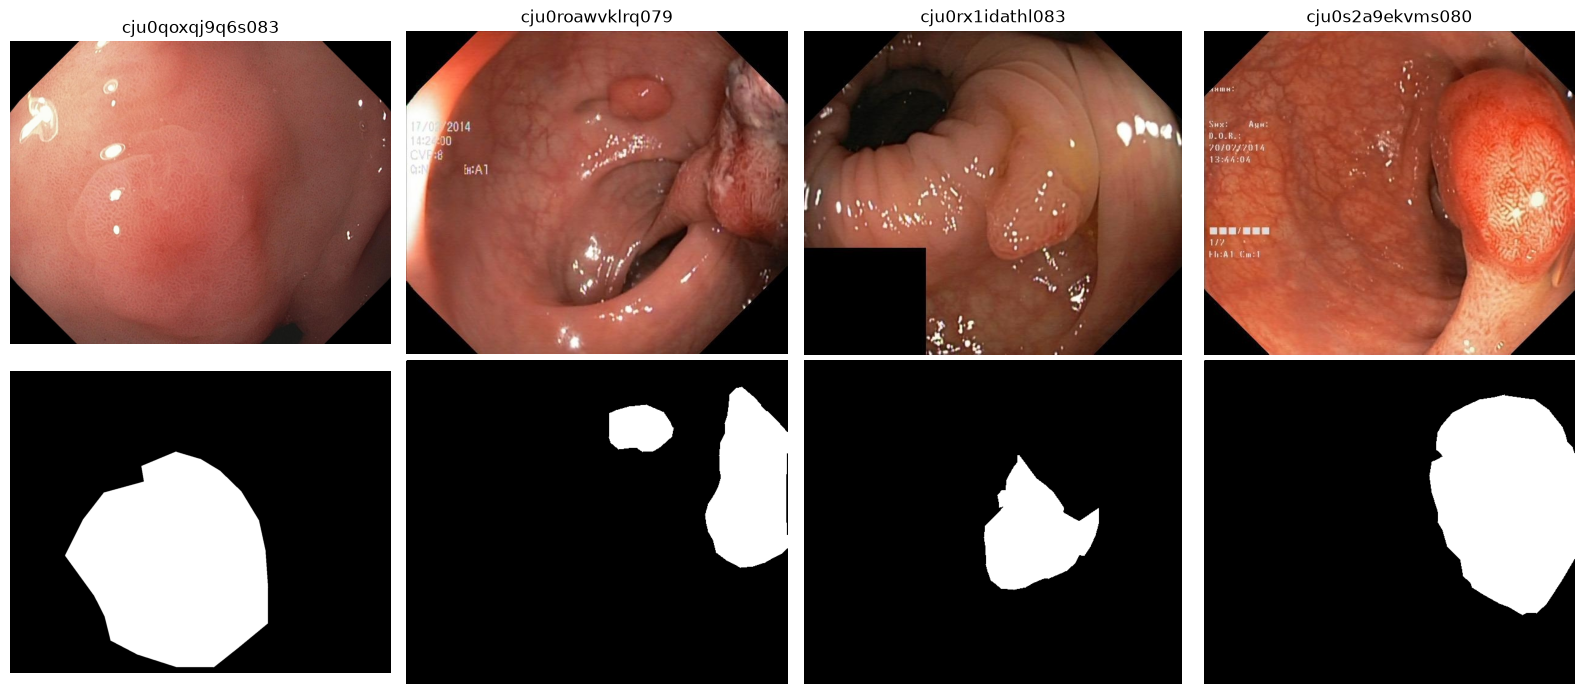

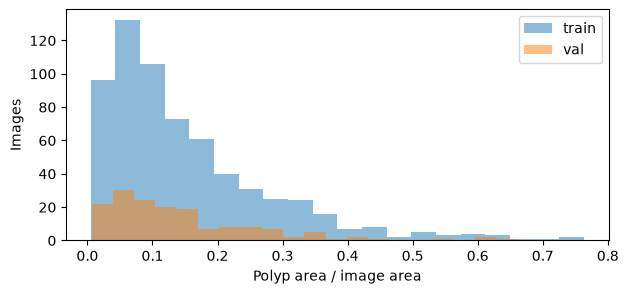

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for col, name in enumerate(split.loc[split['split'].eq('train'), 'name'].head(4)):
    with Image.open(Path(cfg.data) / 'Dataset/images' / name) as im:
        axes[0, col].imshow(im.convert('RGB'))
    with Image.open(Path(cfg.data) / 'Dataset/masks' / name) as m:
        axes[1, col].imshow(np.array(m.convert('L')) > 127, cmap='gray')
    axes[0, col].set_title(name[:16])
for ax in axes.ravel():
    ax.axis('off')
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 3))
for label, part in split.groupby('split'):
    ax.hist(part.area_fraction, bins=20, alpha=0.5, label=label)
ax.set(xlabel='Polyp area / image area', ylabel='Images')
ax.legend()
plt.show()

## 2. 제출 포맷과 사전 검증

예시 파일의 컬럼은 `id,target`, ID는 0–199이며 `Test/images/{id:03}.png`와 대응한다. RLE는 **1-based start/length, 행 우선(C order)** 으로 생성한다. 예시의 반복 간격이 원본 이미지의 너비와 일치하고, C-order로 복호화했을 때 공간 연속성이 유지됨을 확인했다. 대회 페이지는 RLE 방향 자체를 명시하지 않았으므로 이 판단 근거를 기록한다.

- 모든 test 예측은 **각 이미지의 원본 높이·너비**로 복원한다.
- 빈 예측은 빈 문자열로 저장한다.
- 200장 모두 encode/decode round trip과 CSV 재읽기 일치를 검사한다.
- sample_submission의 mask 내용은 정답으로 간주하지 않는다.
- 단위 테스트는 비정사각형 알려진 예제, 빈/전체 마스크, 잘못된 RLE, metric, loss, 실행 잠금을 검증한다.

In [4]:
subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', str(WORK), '-p', 'test_polyp_benchmark.py', '-v'], check=True)
example = np.array([[0, 1, 1], [1, 0, 1]], dtype=np.uint8)
assert benchmark.rle_encode(example) == '2 3 6 1'
print('Known row-major RLE:', benchmark.rle_encode(example))
display(benchmark.status(cfg))

test_empty_full_corners_and_random_roundtrips (test_polyp_benchmark.EncodingTests.test_empty_full_corners_and_random_roundtrips) ... ok
test_invalid_mask_is_rejected (test_polyp_benchmark.EncodingTests.test_invalid_mask_is_rejected) ... ok
test_invalid_rle_is_rejected (test_polyp_benchmark.EncodingTests.test_invalid_rle_is_rejected) ... ok
test_row_major_asymmetric_known_mask (test_polyp_benchmark.EncodingTests.test_row_major_asymmetric_known_mask) ... ok
test_count_based_dice (test_polyp_benchmark.MetricTests.test_count_based_dice) ... ok
test_empty_and_missed_polyp (test_polyp_benchmark.MetricTests.test_empty_and_missed_polyp) ... ok
test_exact_metrics_and_boundary (test_polyp_benchmark.MetricTests.test_exact_metrics_and_boundary) ... ok
test_complete_comparison_analysis_artifacts (test_polyp_benchmark.OutputIntegrationTests.test_complete_comparison_analysis_artifacts) ... 

ok
test_native_size_submission_order_empty_and_full (test_polyp_benchmark.OutputIntegrationTests.test_native_size_submission_order_empty_and_full) ... ok
test_deep_supervision_is_normalized_and_differentiable (test_polyp_benchmark.TrainingTests.test_deep_supervision_is_normalized_and_differentiable) ... ok
test_gpu_and_protocol_defaults (test_polyp_benchmark.TrainingTests.test_gpu_and_protocol_defaults) ... ok
test_persistence_and_concurrent_run_protection (test_polyp_benchmark.TrainingTests.test_persistence_and_concurrent_run_protection) ... ok
test_unet_preserves_dimensions (test_polyp_benchmark.TrainingTests.test_unet_preserves_dimensions) ... ok

----------------------------------------------------------------------
Ran 13 tests in 1.306s

OK


Known row-major RLE: 2 3 6 1


,model,state
0,unet,pending
1,pranet,pending
2,hardnet_mseg,pending
3,dinov2,pending
4,segformer,pending
5,polyp_pvt,pending


## 3. 실제 학습: GPU 1에서 순차 실행

아래 여섯 셀은 각각 최대 50 epoch를 실행하므로 시간이 걸린다. 모델마다 별도 프로세스를 사용해 GPU 메모리와 공식 저장소의 import namespace를 분리한다. GPU 0은 사용하지 않는다. 실행 중에는 각 모델의 `history.csv`, `status.json`, `train_모델명.log`로 진행을 확인할 수 있다.

재실행은 동일 config/code일 때만 허용한다. 완료 모델은 CSV 해시를 확인한 후 건너뛰고, 중단 모델은 마지막 **완료 epoch**의 optimizer/scheduler/scaler/RNG 상태에서 재개한다. 기존 실험을 덮어써 다른 조건을 섞지 않는다. 체크포인트는 신뢰할 수 있는 이 실험의 로컬 파일만 로드한다.

체크포인트 선택은 validation Dice 기준이며, test 또는 sample의 마스크 값으로 선택하지 않는다. 공정한 비교를 위해 전체 train 800장 재학습이나 모델별 threshold tuning을 추가하지 않는다.

In [5]:
run_stage('train', 'unet')
display(pd.read_csv(OUTPUT / 'unet/history.csv').tail())

unet: epoch 1/50, loss=1.3209, native Dice=0.42307, best=0.42307, 33.6s


unet: epoch 2/50, loss=1.2097, native Dice=0.49749, best=0.49749, 33.1s


unet: epoch 3/50, loss=1.1500, native Dice=0.52364, best=0.52364, 33.5s


unet: epoch 4/50, loss=1.1027, native Dice=0.55142, best=0.55142, 33.6s


unet: epoch 5/50, loss=1.0567, native Dice=0.54923, best=0.55142, 33.8s


unet: epoch 6/50, loss=1.0300, native Dice=0.54852, best=0.55142, 33.9s


... (60 outputs left out)

  "submission_sha256": "d8e0b0256a875e40ec899e60c32a609ca857b638b7117a124b4bfe1be8d93ae6"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_unet.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
44,45,0.490847,0.789052,0.692146,41.574272,2.447174e-06
45,46,0.485243,0.787649,0.690146,41.463596,1.570842e-06
46,47,0.479769,0.787597,0.689724,41.589385,8.856375e-07
47,48,0.481961,0.789084,0.691525,41.411787,3.942649e-07
48,49,0.487767,0.785970,0.687806,41.692757,9.866358e-08


In [6]:
run_stage('train', 'pranet')
display(pd.read_csv(OUTPUT / 'pranet/history.csv').tail())

pranet: epoch 1/50, loss=0.9828, native Dice=0.75381, best=0.75381, 26.4s


pranet: epoch 2/50, loss=0.6637, native Dice=0.80309, best=0.80309, 25.7s


pranet: epoch 3/50, loss=0.5250, native Dice=0.86323, best=0.86323, 25.8s


pranet: epoch 4/50, loss=0.4338, native Dice=0.86895, best=0.86895, 25.9s


pranet: epoch 5/50, loss=0.4014, native Dice=0.84713, best=0.86895, 25.9s


pranet: epoch 6/50, loss=0.3576, native Dice=0.85125, best=0.86895, 25.7s


... (38 outputs left out)

  "submission_sha256": "06eff30b0f3c3e87cabc32392524273ceadf1061a18d932962334d7da0fc075b"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_pranet.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
22,23,0.104880,0.886032,0.829533,25.950133,0.000056
23,24,0.091637,0.893325,0.831756,25.750565,0.000053
24,25,0.092726,0.893625,0.832528,25.752159,0.000050
25,26,0.090748,0.893171,0.833018,25.793975,0.000047
26,27,0.080433,0.902195,0.845363,25.680099,0.000044


In [7]:
run_stage('train', 'hardnet_mseg')
display(pd.read_csv(OUTPUT / 'hardnet_mseg/history.csv').tail())

68 LOADED


hardnet_mseg: epoch 1/50, loss=0.9233, native Dice=0.79305, best=0.79305, 20.7s


hardnet_mseg: epoch 2/50, loss=0.6625, native Dice=0.83038, best=0.83038, 19.4s


hardnet_mseg: epoch 3/50, loss=0.5384, native Dice=0.83242, best=0.83242, 19.1s


hardnet_mseg: epoch 4/50, loss=0.4548, native Dice=0.85893, best=0.85893, 19.2s


hardnet_mseg: epoch 5/50, loss=0.4173, native Dice=0.82953, best=0.85893, 19.3s


... (48 outputs left out)

  "submission_sha256": "af3c8443f7a7043de967fe4b81d80288ed6632a0874b9856aa0af8a862d4f0df"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_hardnet_mseg.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
31,32,0.080778,0.893702,0.835087,19.219296,0.000029
32,33,0.077360,0.895805,0.834059,19.636942,0.000026
33,34,0.076686,0.896787,0.836932,19.800160,0.000023
34,35,0.080155,0.891720,0.832592,19.646256,0.000021
35,36,0.073982,0.890836,0.829683,20.873503,0.000018


In [8]:
run_stage('train', 'dinov2')
display(pd.read_csv(OUTPUT / 'dinov2/history.csv').tail())

/home/Data_Drive_8TB/kykim/.conda/envs/scrna/lib/python3.11/site-packages/torch/autograd/graph.py:823: UserWarning: Flash Attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:102.)


  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


dinov2: epoch 1/50, loss=1.1431, native Dice=0.51540, best=0.51540, 16.7s


dinov2: epoch 2/50, loss=1.0476, native Dice=0.32174, best=0.51540, 16.6s


dinov2: epoch 3/50, loss=0.9888, native Dice=0.51415, best=0.51540, 16.5s


dinov2: epoch 4/50, loss=0.9356, native Dice=0.56070, best=0.56070, 16.6s


... (63 outputs left out)

  "submission_sha256": "6669ea5c861f9bd4b2ae52d2f95a1fb41d77d66f7e228bb99948aae626dbe1d3"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_dinov2.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
45,46,0.257307,0.790651,0.692936,15.641127,1.570842e-06
46,47,0.251138,0.789538,0.692157,16.479598,8.856375e-07
47,48,0.246292,0.791650,0.692787,16.788880,3.942649e-07
48,49,0.256223,0.790902,0.693363,16.599390,9.866358e-08
49,50,0.255966,0.789759,0.692729,16.830299,0.000000e+00


In [9]:
run_stage('train', 'segformer')
display(pd.read_csv(OUTPUT / 'segformer/history.csv').tail())

segformer: epoch 1/50, loss=0.6714, native Dice=0.82683, best=0.82683, 90.7s


segformer: epoch 2/50, loss=0.3677, native Dice=0.85751, best=0.85751, 94.3s


segformer: epoch 3/50, loss=0.2803, native Dice=0.88063, best=0.88063, 93.5s


segformer: epoch 4/50, loss=0.2431, native Dice=0.89469, best=0.89469, 93.8s


segformer: epoch 5/50, loss=0.2068, native Dice=0.89990, best=0.89990, 93.8s


segformer: epoch 6/50, loss=0.1968, native Dice=0.89910, best=0.89990, 93.4s


... (52 outputs left out)

  "submission_sha256": "43ed14433f4f3c02036b0fab24a9d608c4d92ceeb539bf370d5029106150a961"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_segformer.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
36,37,0.051634,0.922754,0.874352,84.450936,0.000016
37,38,0.049938,0.923989,0.876246,89.937247,0.000014
38,39,0.050114,0.922556,0.875071,102.807124,0.000011
39,40,0.050300,0.923602,0.875537,120.899216,0.000010
40,41,0.049006,0.921188,0.872443,112.374756,0.000008


In [10]:
run_stage('train', 'polyp_pvt')
display(pd.read_csv(OUTPUT / 'polyp_pvt/history.csv').tail())

/home/Data_Drive_8TB/kykim/.conda/envs/scrna/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers


  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


/home/Data_Drive_8TB/kykim/.conda/envs/scrna/lib/python3.11/site-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models


  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.models", FutureWarning)


/home/Data_Drive_8TB_2/kykim/polyp/benchmark/vendor/Polyp-PVT/lib/pvtv2.py:387: UserWarning: Overwriting pvt_v2_b0 in registry with _polyp_polyp_pvt.pvtv2.pvt_v2_b0. This is because the name being registered conflicts with an existing name. Please check if this is not expected.


  @register_model


... (299 outputs left out)

  "submission_sha256": "45f204688ec6cd2db91027461d741ff6088eb3fbe2323fd74cc5d68a738790d5"


}


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/train_polyp_pvt.log


,epoch,train_loss,val_dice,val_iou,seconds,learning_rate
33,34,0.113894,0.906776,0.854731,28.943430,0.000023
34,35,0.113858,0.909888,0.859203,28.966264,0.000021
35,36,0.108126,0.903274,0.851072,28.949150,0.000018
36,37,0.107510,0.902733,0.850230,29.024539,0.000016
37,38,0.103379,0.907883,0.856096,28.957569,0.000014


## 4. 정량 비교와 불확실성

**주 평가**: 원본 해상도에서 각 이미지 Dice를 계산한 뒤 평균한다. 대회 API는 Dice라고 명시하지만 aggregation 세부 구현은 공개 설명에 없으므로, 참고로 전체 픽셀 global Dice도 함께 기록한다. 부 평가로 IoU, precision, recall, boundary F1을 비교한다.

Boundary F1은 3×3 erosion으로 내부 경계를 구하고, 원본 대각선의 0.5%를 허용 거리(최소 1px)로 둔다. 크기 그룹은 정답 면적 기준 small ≤5%, medium 5–20%, large >20%로 미리 고정한다. 이는 의료적인 크기 분류가 아니라 영상 내 면적 비율이다.

이미지 단위 bootstrap 2,000회로 평균 Dice 95% 구간과 1위 대비 paired difference 구간을 계산한다. **이 구간은 seed 변동·환자 상관관계·최고 epoch/우승 모델 선택 편향을 반영하지 않는다.** 구간이 0을 포함한다고 동등함이 증명되는 것도 아니다. 단일 split 수치를 곧바로 일반적인 CNN vs ViT 우열로 확대하지 않는다.

       model                                label      family  best_epoch  epochs_run  val_dice  val_iou  val_precision  val_recall  val_boundary_f1  val_global_dice  parameters_m  training_seconds  peak_allocated_mb  inference_ms_batch1                                                                          submission                                                submission_sha256  dice_ci_low  dice_ci_high


   segformer                   SegFormer / MiT-B2 Transformer          35          41  0.924062 0.875483       0.936089    0.931721         0.754312         0.926811     27.347393       3766.721454        3300.131348           124.440900    /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/segformer/submission.csv 43ed14433f4f3c02036b0fab24a9d608c4d92ceeb539bf370d5029106150a961     0.903468      0.941114


   polyp_pvt                 Polyp-PVT / PVTv2-B2 Transformer          28          38  0.915446 0.861102       0.938007    0.914543         0.729039         0.920756     25.107604       1933.635519        2463.910156            39.746424    /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/polyp_pvt/submission.csv 45f204688ec6cd2db91027461d741ff6088eb3fbe2323fd74cc5d68a738790d5     0.895531      0.932375


      pranet                  PraNet / Res2Net-50         CNN          17          27  0.903254 0.841296       0.915966    0.916696         0.708726         0.896276     32.547319        697.116939        1698.663574            33.632053       /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/pranet/submission.csv 06eff30b0f3c3e87cabc32392524273ceadf1061a18d932962334d7da0fc075b     0.882916      0.921567


hardnet_mseg            HarDNet-MSEG / HarDNet-68         CNN          26          36  0.901188 0.839295       0.923618    0.909205         0.710174         0.897813     33.343244        705.173731        1113.174805            24.516238 /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/hardnet_mseg/submission.csv af3c8443f7a7043de967fe4b81d80288ed6632a0874b9856aa0af8a862d4f0df     0.880323      0.920375


      dinov2 DINOv2 ViT-S/14 + multilevel decoder Transformer          48          50  0.791650 0.692787       0.816815    0.828254         0.466337         0.811189     22.772801        829.919406        1495.409180            14.270741       /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/dinov2/submission.csv 6669ea5c861f9bd4b2ae52d2f95a1fb41d77d66f7e228bb99948aae626dbe1d3     0.759765      0.824212


        unet                      U-Net (base 32)         CNN          39          49  0.789700 0.689782       0.811920    0.836971         0.481564         0.783327      7.763041       1938.466919        1750.698730             8.330984         /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/unet/submission.csv d8e0b0256a875e40ec899e60c32a609ca857b638b7117a124b4bfe1be8d93ae6     0.756725      0.820031


Saved log: /home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448/analyze_all.log


,label,family,val_dice,dice_ci_low,dice_ci_high,val_iou,val_boundary_f1,val_precision,val_recall,best_epoch,epochs_run,parameters_m,training_seconds,inference_ms_batch1,peak_allocated_mb
0,SegFormer / MiT-B2,Transformer,0.92406,0.90347,0.94111,0.87548,0.75431,0.93609,0.93172,35,41,27.34739,3766.72145,124.44090,3300.13135
1,Polyp-PVT / PVTv2-B2,Transformer,0.91545,0.89553,0.93237,0.86110,0.72904,0.93801,0.91454,28,38,25.10760,1933.63552,39.74642,2463.91016
2,PraNet / Res2Net-50,CNN,0.90325,0.88292,0.92157,0.84130,0.70873,0.91597,0.91670,17,27,32.54732,697.11694,33.63205,1698.66357
3,HarDNet-MSEG / HarDNet-68,CNN,0.90119,0.88032,0.92037,0.83929,0.71017,0.92362,0.90920,26,36,33.34324,705.17373,24.51624,1113.17480
4,DINOv2 ViT-S/14 + multilevel decoder,Transformer,0.79165,0.75976,0.82421,0.69279,0.46634,0.81681,0.82825,48,50,22.77280,829.91941,14.27074,1495.40918
5,U-Net (base 32),CNN,0.78970,0.75672,0.82003,0.68978,0.48156,0.81192,0.83697,39,49,7.76304,1938.46692,8.33098,1750.69873


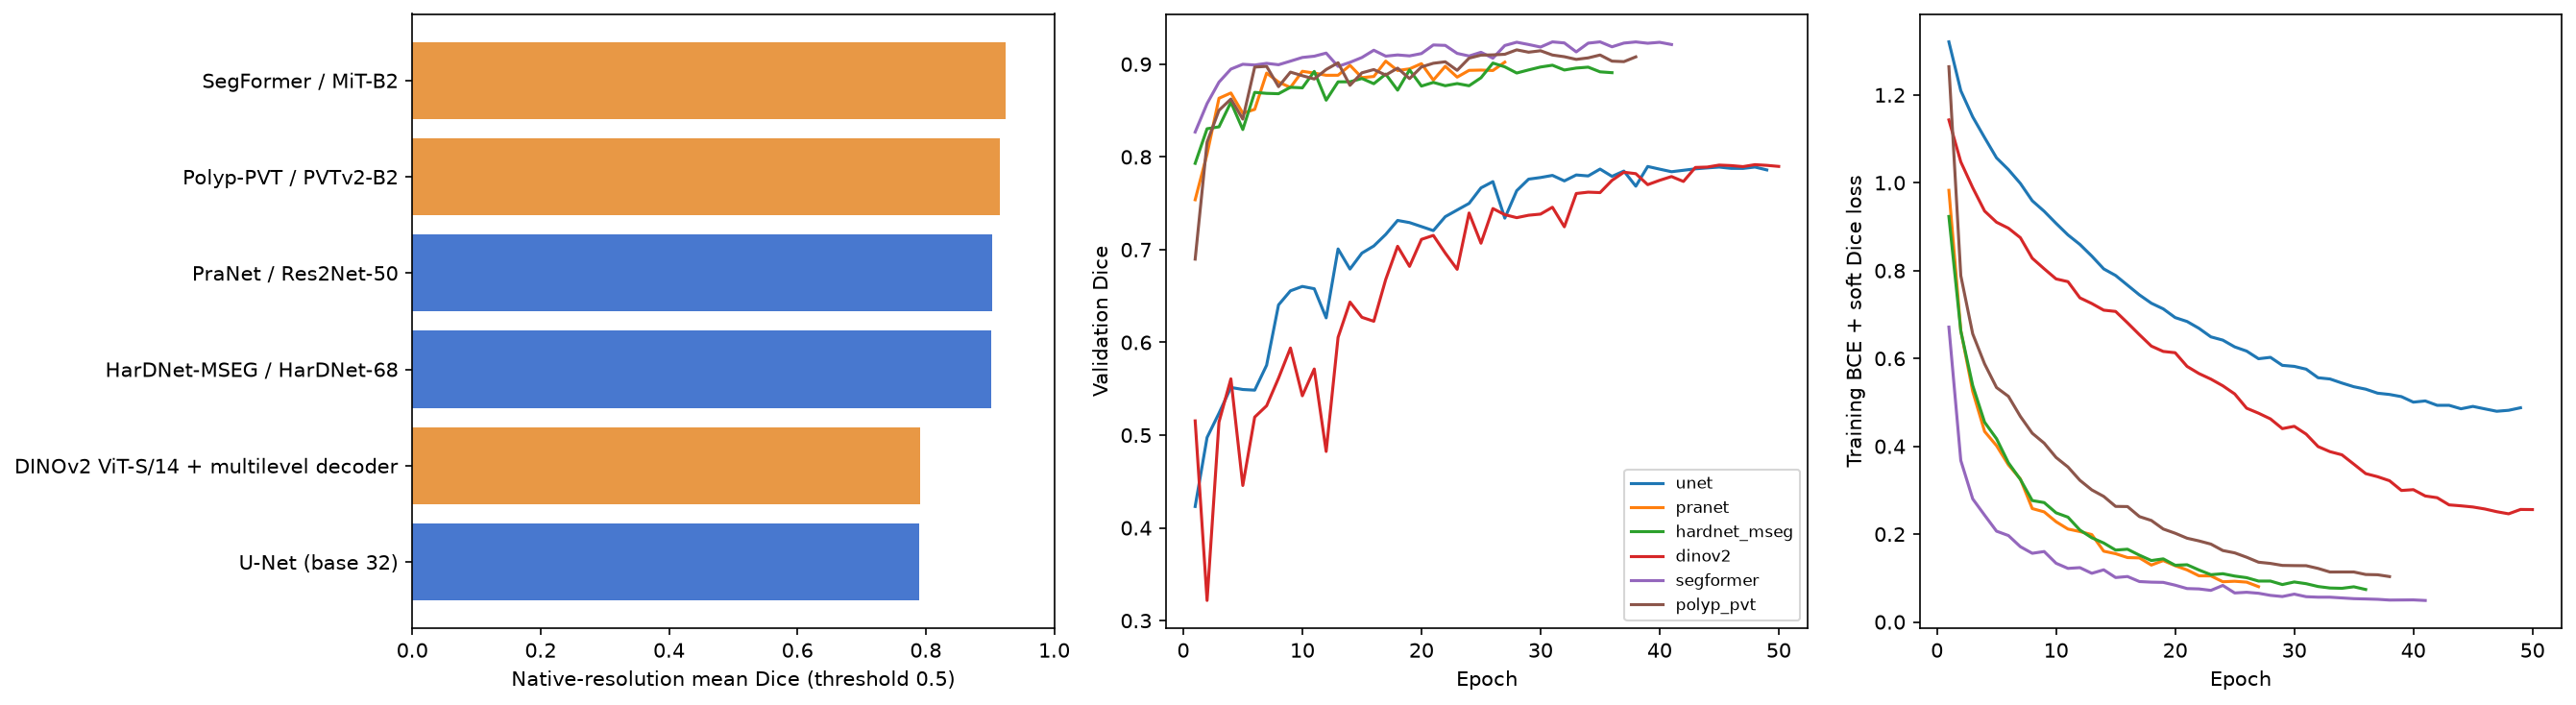

,winner,compared_to,mean_difference,paired_ci_low,paired_ci_high
0,segformer,segformer,0.000000,0.000000,0.000000
1,segformer,polyp_pvt,0.008616,0.000657,0.017178
2,segformer,pranet,0.020808,0.008023,0.033520
3,segformer,hardnet_mseg,0.022874,0.011053,0.036273
4,segformer,dinov2,0.132411,0.106520,0.159633
5,segformer,unet,0.134361,0.108912,0.161344


size_group,large_>20%,medium_5-20%,small_<=5%
model,,,
dinov2,0.801477,0.827581,0.687670
hardnet_mseg,0.890875,0.908275,0.894370
polyp_pvt,0.921671,0.923432,0.887816
pranet,0.891475,0.911879,0.894095
segformer,0.928800,0.926575,0.912258
unet,0.778575,0.836035,0.682208


,model,size_group,n,recall
0,segformer,small_<=5%,34,0.935568
1,segformer,medium_5-20%,88,0.932489
2,segformer,large_>20%,38,0.926499
3,polyp_pvt,small_<=5%,34,0.905380
4,polyp_pvt,medium_5-20%,88,0.921786
5,polyp_pvt,large_>20%,38,0.905965
6,pranet,small_<=5%,34,0.920695
7,pranet,medium_5-20%,88,0.929928
8,pranet,large_>20%,38,0.882474
9,hardnet_mseg,small_<=5%,34,0.925397


In [11]:
run_stage('analyze')
results = pd.read_csv(OUTPUT / 'comparison.csv')
assert len(results) == 6
columns = ['label', 'family', 'val_dice', 'dice_ci_low', 'dice_ci_high', 'val_iou', 'val_boundary_f1', 'val_precision', 'val_recall', 'best_epoch', 'epochs_run', 'parameters_m', 'training_seconds', 'inference_ms_batch1', 'peak_allocated_mb']
display(results[columns].round(5))
display(DisplayImage(filename=str(OUTPUT / 'comparison.png')))
paired = pd.read_csv(OUTPUT / 'paired_bootstrap.csv')
display(paired)
sizes = pd.read_csv(OUTPUT / 'size_analysis.csv')
display(sizes.pivot(index='model', columns='size_group', values='dice'))
display(sizes[['model', 'size_group', 'n', 'recall']])

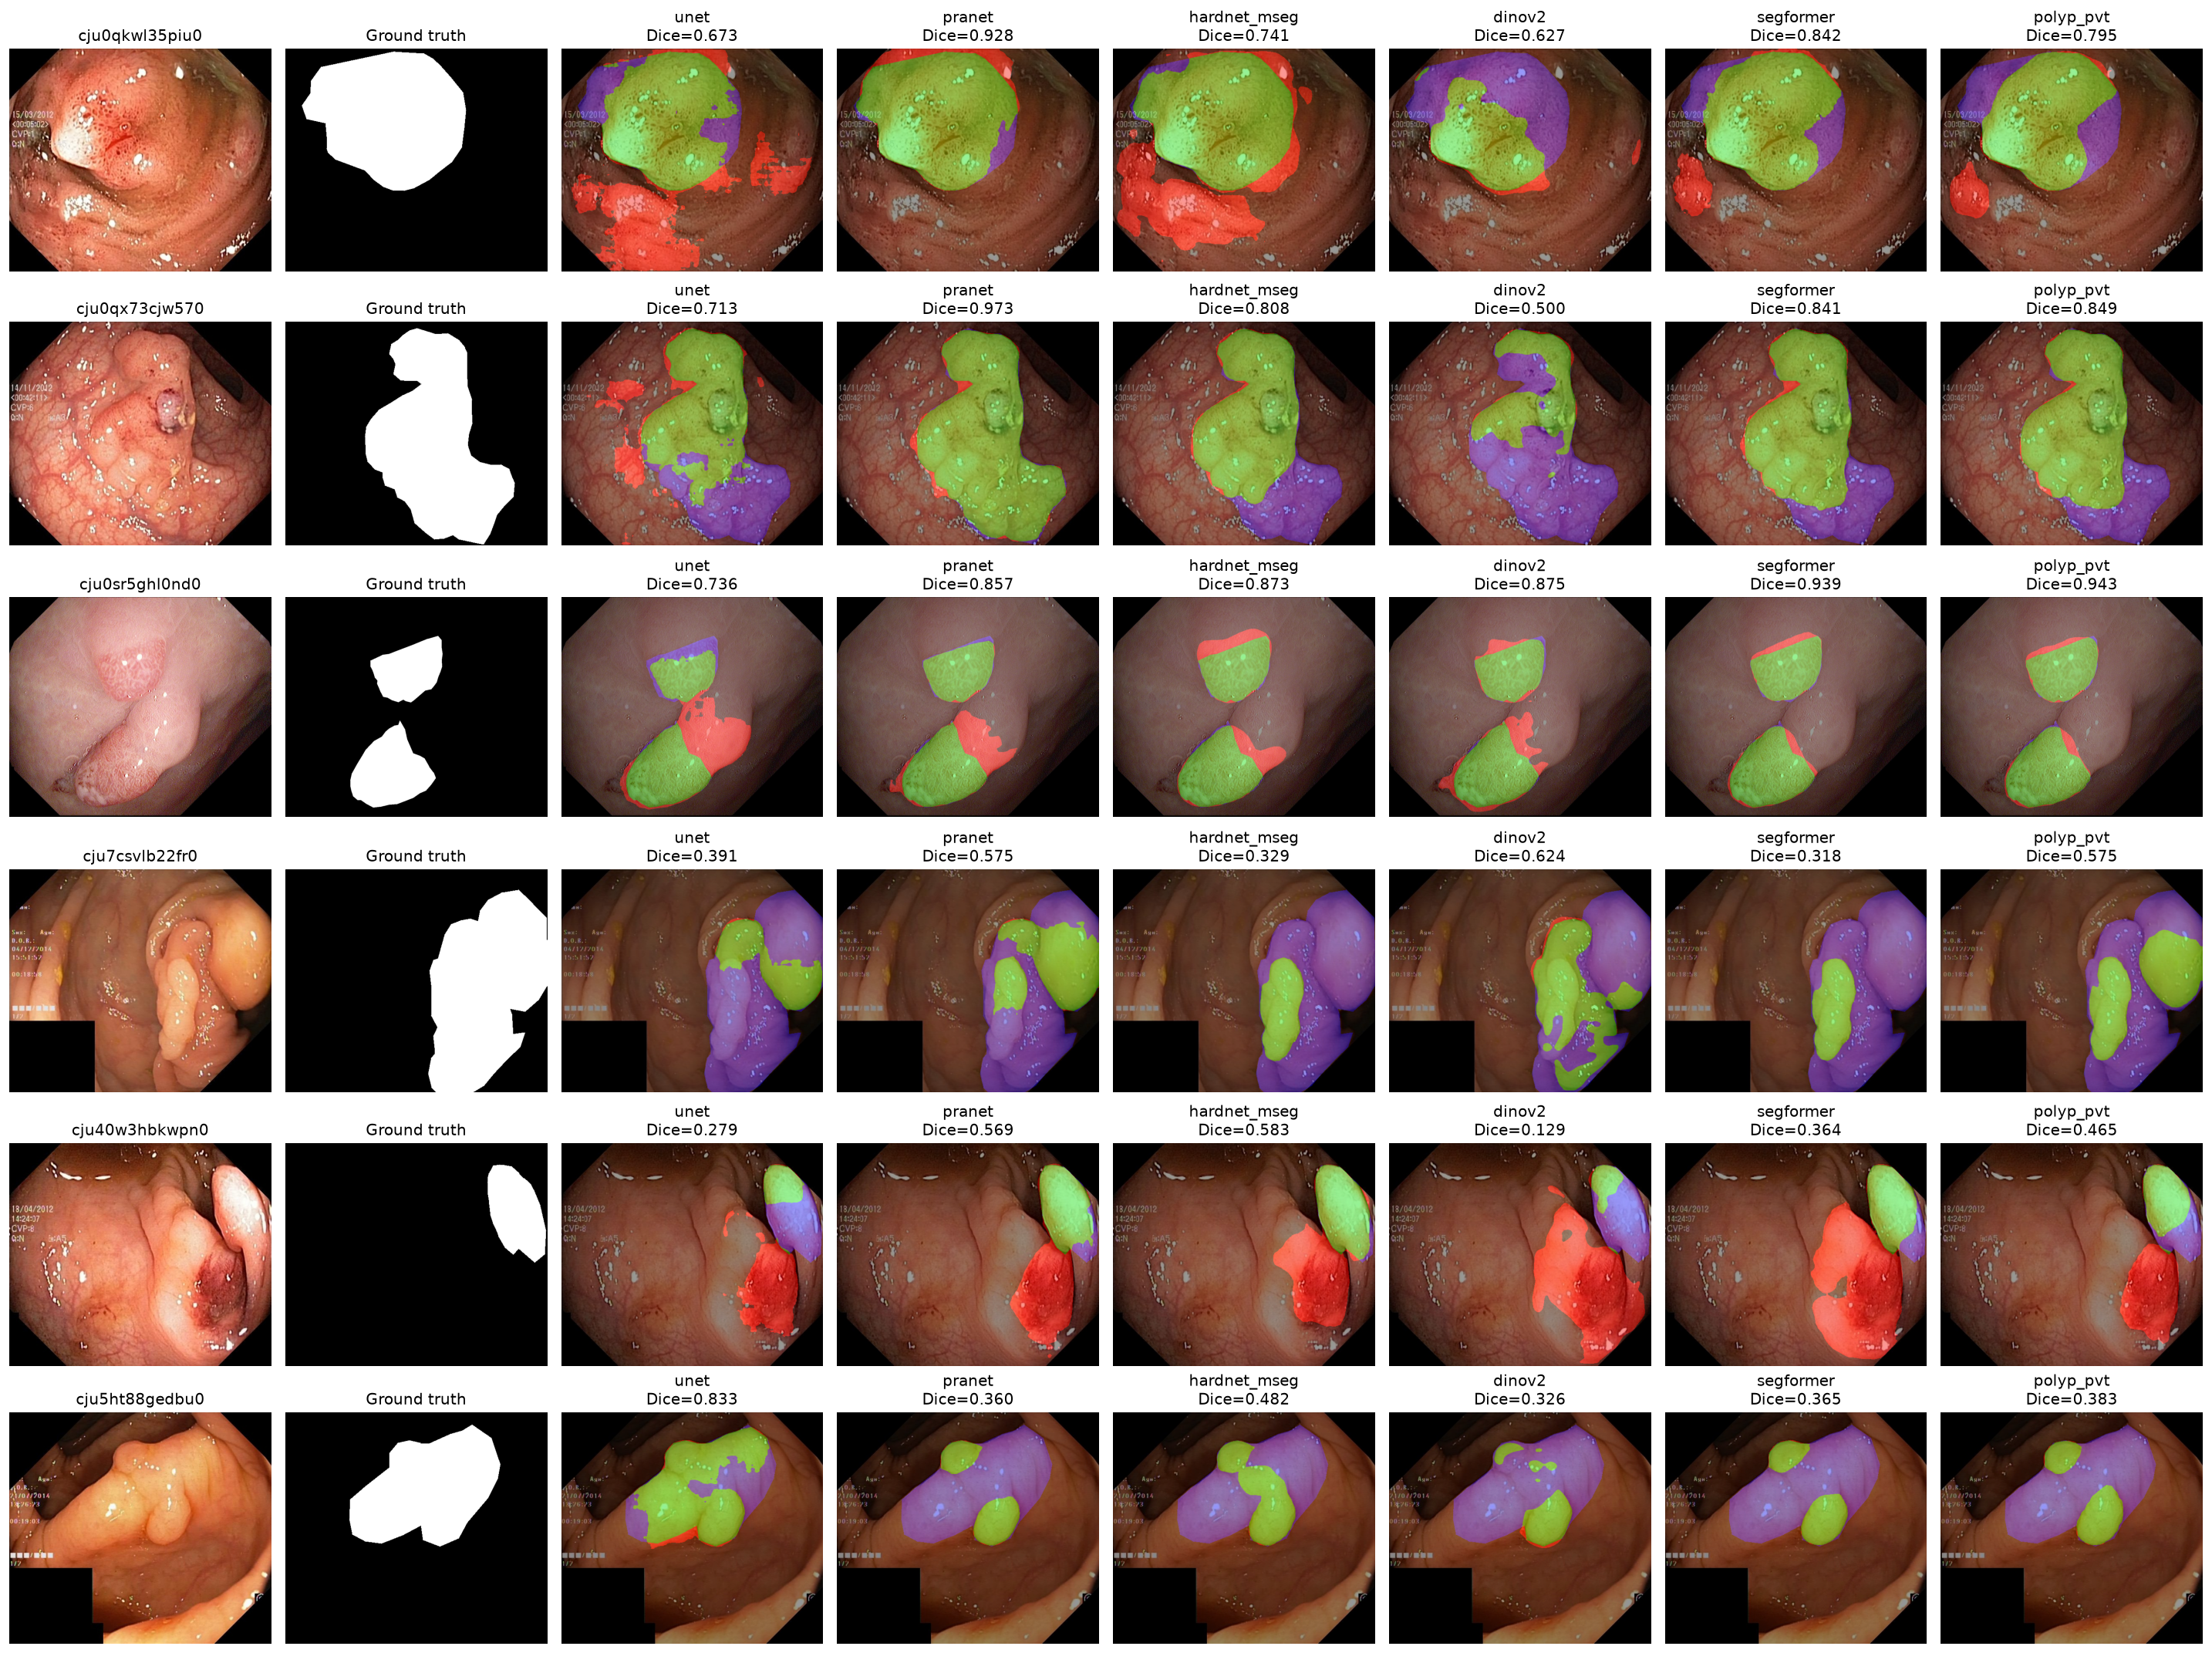

### 관측 결과
- 이 고정 validation 분할의 1위: **SegFormer / MiT-B2**, mean Dice **0.9241**
- CNN 중 최고: PraNet / Res2Net-50 (0.9033)
- Transformer 중 최고: SegFormer / MiT-B2 (0.9241)
- 이는 이 실험의 관측 순위이며 숨겨진 test 성능이나 모델 계열 전체의 우열은 아니다.

Overlay: green=TP, red=FP (over-segmentation), blue=FN (missed polyp).
Examples: three fixed validation filenames + three worst images of the validation winner; not a random representative sample.
Winner difference interval includes zero for: []


In [ ]:
display(DisplayImage(filename=str(OUTPUT / 'qualitative_comparison.png')))
winner = results.iloc[0]
best_cnn = results.loc[results.family.eq('CNN')].iloc[0]
best_transformer = results.loc[results.family.eq('Transformer')].iloc[0]
display(Markdown(f'### 관측 결과\n- 이 고정 validation 분할의 1위: **{winner["label"]}**, mean Dice **{winner["val_dice"]:.4f}**\n- CNN 중 최고: {best_cnn["label"]} ({best_cnn["val_dice"]:.4f})\n- Transformer 중 최고: {best_transformer["label"]} ({best_transformer["val_dice"]:.4f})\n- 이는 이 실험의 관측 순위이며 숨겨진 test 성능이나 모델 계열 전체의 우열은 아니다.'))
print('Overlay: green=TP, red=FP (over-segmentation), blue=FN (missed polyp).')
print('Examples: three fixed validation filenames + three worst images of the validation winner; not a random representative sample.')
uncertain = paired.loc[(paired.compared_to != winner['model']) & (paired.paired_ci_low <= 0) & (paired.paired_ci_high >= 0), 'compared_to'].tolist()
print('Winner difference interval includes zero for:', uncertain)

## 5. 나의 해석: 수치에서 설명으로

아래 질문에 실제 표·그림을 근거로 본인의 해석을 추가한다. 구조를 근거로 한 설명은 인과 증명이 아니라 **가설**로 표현한다.

1. **주 성능**: 최고 Dice 모델이 IoU·경계 성능에서도 높은가? 평균 점수와 최악 사례가 일치하는가?
2. **작은 용종**: small 그룹의 Dice/recall이 낮은 모델은 무엇인가? 패치/다운샘플링과 관련 있을 가능성이 있는가? 각 그룹의 표본 수도 함께 보고한다.
3. **경계와 오류 방향**: 빨강(FP)과 파랑(FN) 중 어떤 오류가 많은가? 높은 precision이 낮은 recall을 숨기지는 않는가?
4. **구조 가설**: U-Net skip connection, PraNet reverse attention, HarDNet feature reuse, DINO 표현학습, SegFormer 다중 스케일, PVT CFM/CIM/SAM과 관측 결과를 연결하되 구조만의 효과라고 단정하지 않는다.
5. **효율**: Dice 증가 폭이 학습 시간·파라미터·지연시간 증가를 정당화하는가? latency는 batch 1, 448 입력, GPU forward만 측정하며 디스크 읽기/RLE 시간은 제외한다. 메모리는 PyTorch peak allocated로 nvidia-smi 전체 점유량과 다르다.
6. **불확실성**: paired 구간이 0을 포함하는가? single split/seed와 pretrained corpus 차이, random-init U-Net의 한계를 밝힌다. 일반화 주장은 다중 seed, patient-group split 또는 외부 데이터 검증으로 확인해야 한다.

### 나의 최종 해석

학습 완료 후 이 위치에 본인의 해석을 작성한다. 자동 생성된 순위와 달리, 본인의 판단 근거·예외 사례·후속 실험 제안을 명확히 분리한다.

> 임상 효용이나 안전성을 검증한 실험이 아니며 의료 현장 적용 결론을 내리지 않는다.

## 6. CSV 6개 확인 — 업로드 없음

각 모델 폴더의 `submission.csv`를 그대로 보존한다. 모델별 best validation checkpoint를 사용하며 hidden test 정답은 없다. **CSV 생성 완료와 Kaggle 제출/채점 완료는 다르다.** 현재 요청에 따라 Kaggle CLI는 실행하지 않는다.

향후 규칙·라이선스·마감 후 제출 허용 여부를 별도로 확인하고 직접 업로드할 때의 형식:

```bash
kaggle competitions submit -c polyp-segmentation -f /path/to/model/submission.csv -m "model / seed42 / validation-selected checkpoint"
```

모델을 비교하기 위한 핵심 산출물은 `comparison.csv`, `paired_bootstrap.csv`, `size_analysis.csv`, 원본 해상도 검증 마스크, `comparison.png`, `qualitative_comparison.png`이다. sample 파일이나 원본 이미지는 수정하지 않는다.

In [13]:
manifest = pd.read_csv(OUTPUT / 'test_manifest.csv')
artifacts = []
for model_name in benchmark.MODELS:
    path = OUTPUT / model_name / 'submission.csv'
    submission = pd.read_csv(path, keep_default_na=False)
    assert list(submission.columns) == ['id', 'target']
    assert submission.id.tolist() == manifest.id.tolist()
    for row, item in zip(submission.itertuples(index=False), manifest.itertuples(index=False)):
        decoded = benchmark.rle_decode(row.target, (item.height, item.width))
        assert benchmark.rle_encode(decoded) == row.target
    artifacts.append({'model': model_name, 'rows': len(submission), 'csv': str(path), 'uploaded': False})
display(pd.DataFrame(artifacts))
print('6개 CSV 생성·검증 완료. Kaggle 업로드는 수행하지 않았습니다.')

,model,rows,csv,uploaded
0,unet,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False
1,pranet,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False
2,hardnet_mseg,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False
3,dinov2,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False
4,segformer,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False
5,polyp_pvt,200,/home/Data_Drive_8TB_2/kykim/polyp/benchmark/s...,False


6개 CSV 생성·검증 완료. Kaggle 업로드는 수행하지 않았습니다.


## 7. 모델별 validation 및 Kaggle Public bar plot

아래 셀은 학습을 다시 실행하지 않고 저장된 실제 결과만 읽는다. 모델 순서는 CNN 3종 → Transformer 3종으로 고정하며, 모든 y축은 0–1이다. 각 막대 위에는 소수점 넷째 자리까지 표시한다.

1. **Validation 지표 6개**: mean Dice, mean IoU, mean precision, mean recall, mean boundary F1, global Dice를 각각 별도의 패널로 비교한다. Global Dice는 전체 이미지 픽셀의 TP/FP/FN을 합쳐 계산하므로 이미지별 mean Dice와 다르다.
2. **Validation Dice vs Public Dice**: 동일 모델의 로컬 validation 점수와 Kaggle Public 점수를 나란히 비교한다. 두 점수는 서로 다른 데이터에서 계산되므로 차이를 곧바로 과적합의 크기로 단정하지 않는다.

**제출 상태 정정**: 앞의 6절과 학습 실행 출력에 적힌 '업로드 없음'은 최초 실행 범위의 기록이다. 이후 사용자 요청에 따라 6개 모두 제출했으며 Kaggle 서버에서 모두 COMPLETE를 확인했다. 아래 셀은 실제 제출 메시지·CSV 해시와 일치하는 서버 결과만 사용하며 Private 점수는 이 그림에 포함하지 않는다. 최신 서버 조회 실패 또는 채점 미완료 시 임의 값으로 대체하지 않고 오류를 표시한다.

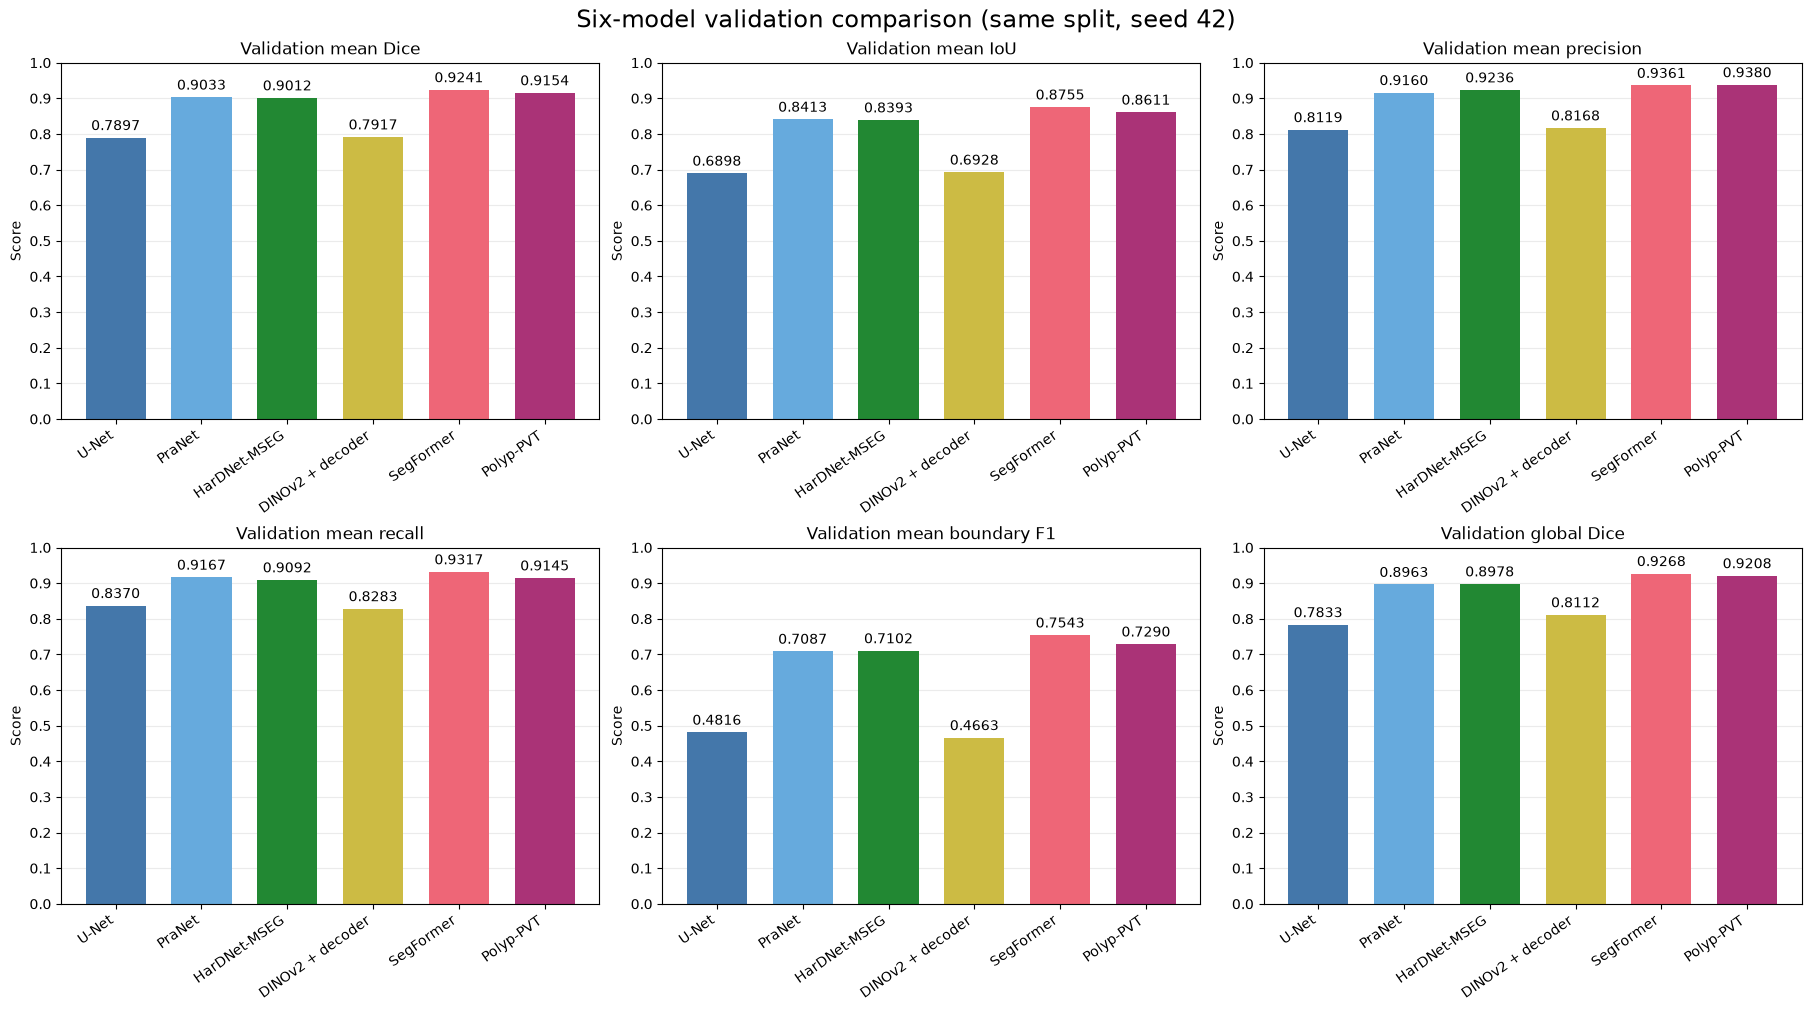

,val_dice,val_iou,val_precision,val_recall,val_boundary_f1,val_global_dice
model,,,,,,
U-Net,0.789700,0.689782,0.811920,0.836971,0.481564,0.783327
PraNet,0.903254,0.841296,0.915966,0.916696,0.708726,0.896276
HarDNet-MSEG,0.901188,0.839295,0.923618,0.909205,0.710174,0.897813
DINOv2 + decoder,0.791650,0.692787,0.816815,0.828254,0.466337,0.811189
SegFormer,0.924062,0.875483,0.936089,0.931721,0.754312,0.926811
Polyp-PVT,0.915446,0.861102,0.938007,0.914543,0.729039,0.920756


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BAR_OUTPUT = Path('/home/Data_Drive_8TB_2/kykim/polyp/benchmark/seed42_448')
bar_models = ['unet', 'pranet', 'hardnet_mseg', 'dinov2', 'segformer', 'polyp_pvt']
bar_labels = ['U-Net', 'PraNet', 'HarDNet-MSEG', 'DINOv2 + decoder', 'SegFormer', 'Polyp-PVT']
bar_colors = ['#4477AA', '#66AADD', '#228833', '#CCBB44', '#EE6677', '#AA3377']
bar_metrics = {
    'val_dice': 'Validation mean Dice',
    'val_iou': 'Validation mean IoU',
    'val_precision': 'Validation mean precision',
    'val_recall': 'Validation mean recall',
    'val_boundary_f1': 'Validation mean boundary F1',
    'val_global_dice': 'Validation global Dice',
}
bar_validation = pd.read_csv(BAR_OUTPUT / 'comparison.csv').set_index('model')
if not bar_validation.index.is_unique or set(bar_validation.index) != set(bar_models):
    raise ValueError('Expected exactly one completed result for each of the six models.')
bar_validation = bar_validation.loc[bar_models, list(bar_metrics)].copy()
if not np.isfinite(bar_validation.to_numpy()).all() or not ((bar_validation >= 0) & (bar_validation <= 1)).all().all():
    raise ValueError('Validation scores must all be finite and between 0 and 1.')
for model_name in bar_models:
    original_result = json.loads((BAR_OUTPUT / model_name / 'result.json').read_text())
    for metric in bar_metrics:
        if not np.isclose(bar_validation.loc[model_name, metric], original_result[metric], rtol=0, atol=1e-12):
            raise ValueError(f'Comparison and checkpoint result differ: {model_name}, {metric}')

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True)
for ax, (metric, title) in zip(axes.ravel(), bar_metrics.items()):
    bars = ax.bar(bar_labels, bar_validation[metric], color=bar_colors, width=0.7)
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=10)
    ax.set(title=title, ylabel='Score', ylim=(0, 1))
    ax.tick_params(axis='x', labelrotation=35)
    for tick in ax.get_xticklabels():
        tick.set_ha('right')
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Six-model validation comparison (same split, seed 42)', fontsize=17)
fig.savefig(BAR_OUTPUT / 'validation_metrics_barplots.png', dpi=200, bbox_inches='tight')
fig.savefig(BAR_OUTPUT / 'validation_metrics_barplots.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
bar_validation.to_csv(BAR_OUTPUT / 'validation_barplot_values.csv')
display(bar_validation.rename(index=dict(zip(bar_models, bar_labels))).round(6))

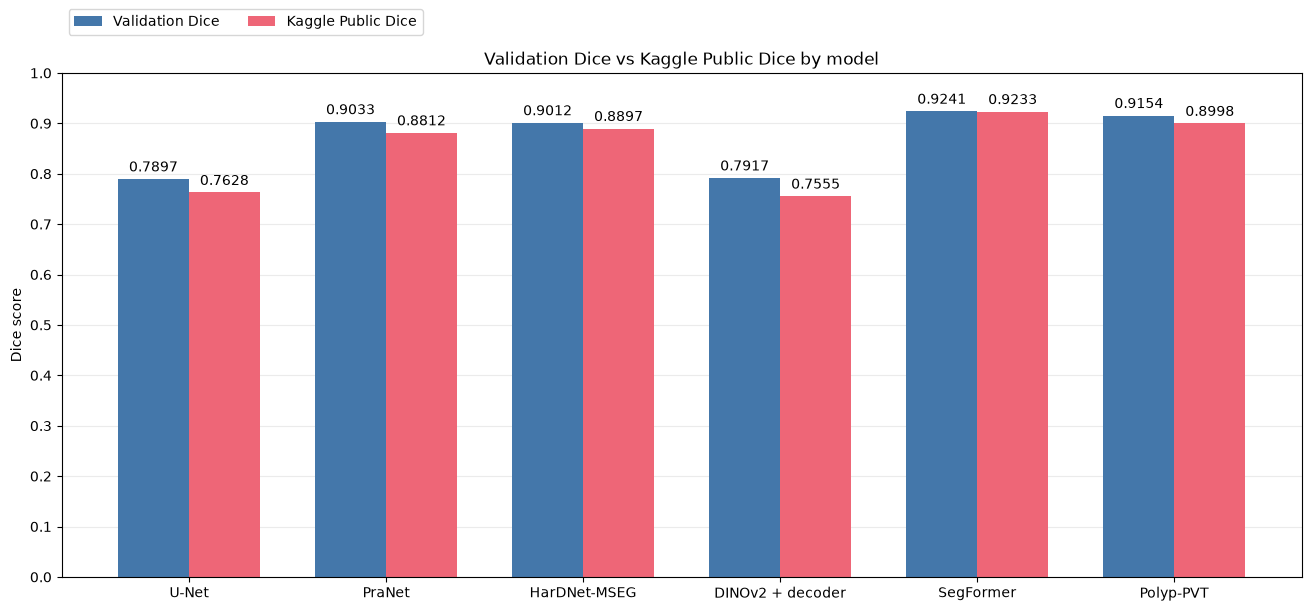

,submission_ref,val_dice,public_dice,status
model,,,,
U-Net,57992215,0.789700,0.76284,SubmissionStatus.COMPLETE
PraNet,57992219,0.903254,0.88121,SubmissionStatus.COMPLETE
HarDNet-MSEG,57992220,0.901188,0.88970,SubmissionStatus.COMPLETE
DINOv2 + decoder,57992221,0.791650,0.75549,SubmissionStatus.COMPLETE
SegFormer,57992222,0.924062,0.92330,SubmissionStatus.COMPLETE
Polyp-PVT,57992223,0.915446,0.89984,SubmissionStatus.COMPLETE


Validated six COMPLETE submissions. Plots saved as PNG and PDF; no new uploads performed.


In [2]:
import io
import subprocess

# Read-only server query; this cell never uploads or retrains a model.
server_query = subprocess.run(
    ['kaggle', 'competitions', 'submissions', '-c', 'polyp-segmentation', '--csv'],
    capture_output=True, text=True, check=True, timeout=120,
)
server_lines = server_query.stdout.splitlines()
header = next((i for i, line in enumerate(server_lines) if line.startswith('ref,fileName,')), None)
if header is None:
    raise RuntimeError(f'Kaggle did not return a submissions CSV: {server_query.stdout}\n{server_query.stderr}')
server_scores = pd.read_csv(io.StringIO('\n'.join(server_lines[header:])), dtype={'ref': str})
submission_registry = json.loads((BAR_OUTPUT / 'kaggle_submission_status.json').read_text())
public_rows = []
for model_name in bar_models:
    from hashlib import sha256
    submitted_path = BAR_OUTPUT / model_name / 'submission.csv'
    current_sha = sha256(submitted_path.read_bytes()).hexdigest()
    result_record = json.loads((BAR_OUTPUT / model_name / 'result.json').read_text())
    attempt = submission_registry['attempts'][model_name]
    if current_sha != attempt['submission_sha256'] or current_sha != result_record['submission_sha256']:
        raise ValueError(f'Submitted CSV hash mismatch: {model_name}')
    matching = server_scores.loc[server_scores.description.eq(attempt['message'])]
    if len(matching) != 1:
        raise ValueError(f'Expected one exact server submission for {model_name}, found {len(matching)}')
    server_row = matching.iloc[0]
    if server_row.status != 'SubmissionStatus.COMPLETE':
        raise RuntimeError(f'{model_name} scoring is not complete: {server_row.status}')
    public = float(server_row.publicScore)
    if not np.isfinite(public) or not 0 <= public <= 1:
        raise ValueError(f'Invalid Kaggle Public score: {model_name}')
    public_rows.append({'model': model_name, 'submission_ref': server_row['ref'],
                        'val_dice': bar_validation.loc[model_name, 'val_dice'],
                        'public_dice': public, 'status': server_row.status})
bar_submission = pd.DataFrame(public_rows).set_index('model').loc[bar_models]
bar_submission.to_csv(BAR_OUTPUT / 'validation_public_barplot_values.csv')

x = np.arange(len(bar_models))
width = 0.36
fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
validation_bars = ax.bar(x - width / 2, bar_submission.val_dice, width, label='Validation Dice', color='#4477AA')
public_bars = ax.bar(x + width / 2, bar_submission.public_dice, width, label='Kaggle Public Dice', color='#EE6677')
for bars in [validation_bars, public_bars]:
    ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=10)
ax.set(title='Validation Dice vs Kaggle Public Dice by model', ylabel='Dice score', ylim=(0, 1))
ax.set_xticks(x, bar_labels)
ax.set_yticks(np.arange(0, 1.01, 0.1))
ax.set_axisbelow(True)
ax.grid(axis='y', alpha=0.25)
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.14), ncol=2)
fig.savefig(BAR_OUTPUT / 'validation_vs_public_barplot.png', dpi=200, bbox_inches='tight')
fig.savefig(BAR_OUTPUT / 'validation_vs_public_barplot.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
display(bar_submission.rename(index=dict(zip(bar_models, bar_labels))))
print('Validated six COMPLETE submissions. Plots saved as PNG and PDF; no new uploads performed.')